In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
# Load stock dataset
df_stock = pd.read_csv('C:\\Users\win\\OneDrive\\Desktop\\stock_prices.csv')
df_stock['Date'] = pd.to_datetime(df_stock['Date'])
df_stock = df_stock.sort_values('Date').reset_index(drop=True)

In [4]:
print("Dataset Loaded Successfully!")
print("Total Trading Days:", df_stock.shape[0])
df_stock.head(3)

Dataset Loaded Successfully!
Total Trading Days: 1000


,Date,Open,High,Low,Close,Volume
0,2023-01-01,168.73,169.66,167.42,168.93,1438601
1,2023-01-02,197.54,200.25,196.31,199.45,896308
2,2023-01-03,186.60,190.96,182.07,184.30,1601887


## Train-Test Split

In [5]:

X = df_stock[['Open', 'High', 'Low', 'Volume']]
y = df_stock['Close']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 800
Testing Records: 200


## Linear Regression and Random Forest Regressor

In [6]:
# 1. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

# 2. Random Forest Regressor
rf_stock = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf_stock.fit(X_train, y_train)
rf_pred = rf_stock.predict(X_test)

# Compare Results
print("--- Model Performance ---")
print(f"Linear Regression | MAE: {mean_absolute_error(y_test, lr_pred):.3f} | R2 Score: {r2_score(y_test, lr_pred):.3f}")
print(f"Random Forest     | MAE: {mean_absolute_error(y_test, rf_pred):.3f} | R2 Score: {r2_score(y_test, rf_pred):.3f}")

--- Model Performance ---
Linear Regression | MAE: 1.320 | R2 Score: 0.987
Random Forest     | MAE: 1.448 | R2 Score: 0.984


## Stock Price History & 20-Day Moving Average

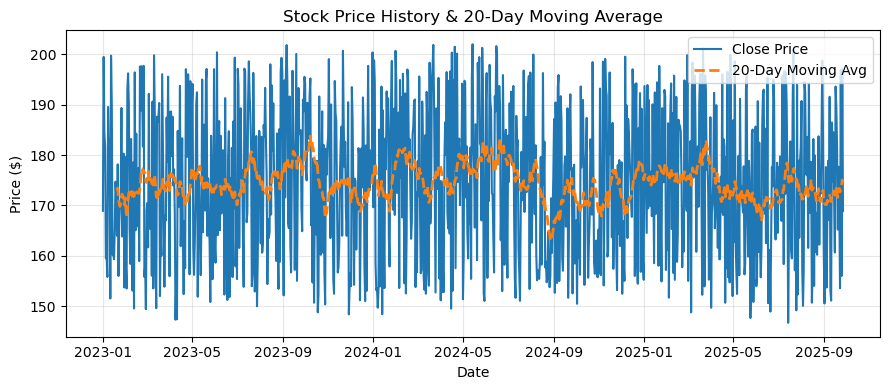

In [7]:
plt.figure(figsize=(9, 4))
df_stock['MA_20'] = df_stock['Close'].rolling(20).mean()

plt.plot(df_stock['Date'], df_stock['Close'], label='Close Price', color='#1f77b4', lw=1.5)
plt.plot(df_stock['Date'], df_stock['MA_20'], label='20-Day Moving Avg', color='#ff7f0e', lw=2, linestyle='--')
plt.title('Stock Price History & 20-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Stock Market: Actual vs Predicted Close Price

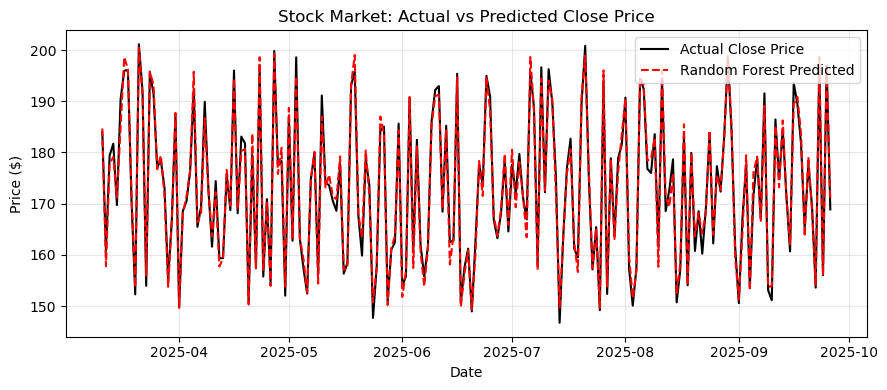

In [8]:
plt.figure(figsize=(9, 4))
test_dates = df_stock.loc[X_test.index, 'Date']

plt.plot(test_dates.values, y_test.values, label='Actual Close Price', color='black', lw=1.5)
plt.plot(test_dates.values, rf_pred, label='Random Forest Predicted', color='red', linestyle='--', lw=1.5)
plt.title('Stock Market: Actual vs Predicted Close Price')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# New day market inputs
sample_day = pd.DataFrame([{
    'Open': 180.50,
    'High': 185.00,
    'Low': 179.20,
    'Volume': 1200000
}])

predicted_price = rf_stock.predict(sample_day)[0]
print("=" * 45)
print(f"Predicted Closing Price: ${predicted_price:.2f}")
print("=" * 45)

Predicted Closing Price: $181.67
